## Experiment: an outlier and the sample mean.

Mean: 56.00 -> 69.09


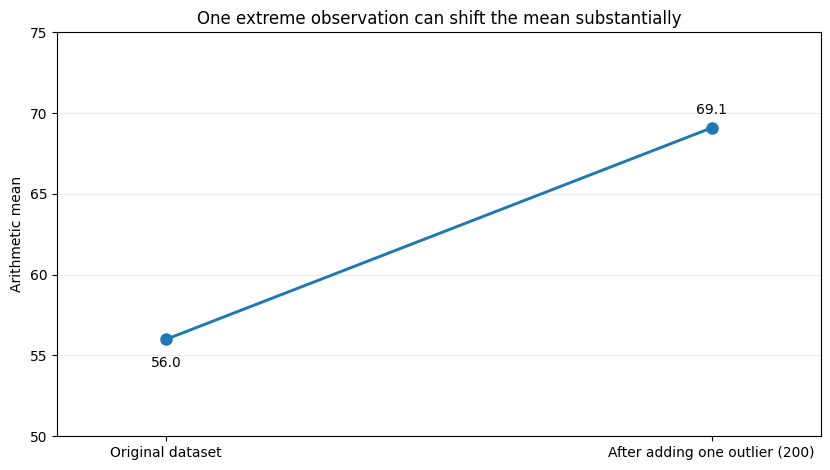

In [1]:
import numpy as np
import matplotlib.pyplot as plt

data = np.array([42, 47, 50, 51, 55, 58, 60, 62, 65, 70], dtype=float)
with_outlier = np.append(data, 200)

means = [np.mean(data), np.mean(with_outlier)]
print(f"Mean: {means[0]:.2f} -> {means[1]:.2f}")

x = np.arange(2)

fig, ax = plt.subplots(figsize=(8.5, 4.8))

ax.plot(x, means, marker="o", linewidth=2.1, markersize=8)

for i, value in enumerate(means):
    ax.annotate(f"{value:.1f}", (i, value), xytext=(0, -20 if i == 0 else 10),
                textcoords="offset points", ha="center", fontsize=10)

ax.set_xticks(x, ["Original dataset", "After adding one outlier (200)"])
ax.set_xlim(-0.2, 1.2)
ax.set_ylim(50, 75)
ax.set_ylabel("Arithmetic mean")
ax.set_title("One extreme observation can shift the mean substantially")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig("../../images/means_outlier_experiment.png", dpi=180, bbox_inches="tight")
plt.show()

## Experiment: averaging subgroup means correctly.

In [2]:
import numpy as np

group_sizes = np.array([10, 90])
group_means = np.array([80.0, 60.0])

naive_mean = np.mean(group_means)  # Treats the groups as equally large.
overall_mean = np.average(group_means, weights=group_sizes)

print(f"Unweighted mean of group means: {naive_mean:.1f}")
print(f"Mean over all individuals:    {overall_mean:.1f}")

Unweighted mean of group means: 70.0
Mean over all individuals:    62.0


## Experiment: conversion rates in a Pandas DataFrame.

In [3]:
import pandas as pd

# Counts and conversion rates reported for four days/channels.
daily = pd.DataFrame({
    "channel": ["Organic", "Organic", "Ads", "Ads"],
    "sessions": [100, 120, 10, 20],
    "conversions": [4, 6, 2, 2],
})
daily["conversion_rate"] = daily["conversions"] / daily["sessions"]

# Incorrect if we want the rate over ALL sessions:
average_of_rates = daily["conversion_rate"].mean()

# Correct: ratio of totals = denominator-weighted mean of rates.
overall_rate = daily["conversions"].sum() / daily["sessions"].sum()
by_channel = daily.groupby("channel", as_index=False).agg(
    sessions=("sessions", "sum"),
    conversions=("conversions", "sum"),
)
by_channel["conversion_rate"] = (
    by_channel["conversions"] / by_channel["sessions"]
)

print(f"Naive mean of four rates: {average_of_rates:.2%}")
print(f"Overall session conversion rate: {overall_rate:.2%}")
print(by_channel.to_string(index=False))

Naive mean of four rates: 9.75%
Overall session conversion rate: 5.60%
channel  sessions  conversions  conversion_rate
    Ads        30            4         0.133333
Organic       220           10         0.045455


## Experiment: the annualized compound growth rate.

In [4]:
from math import prod
from scipy.stats import gmean

annual_rates = [0.02, 0.05]
growth_factors = [1 + rate for rate in annual_rates]
initial_population = 1_000_000

actual_final = initial_population * prod(growth_factors)
equivalent_factor = gmean(growth_factors)
equivalent_rate = equivalent_factor - 1
reproduced_final = initial_population * equivalent_factor ** len(annual_rates)

print(f"Final population: {actual_final:,.0f}")
print(f"Equivalent annual growth: {100 * equivalent_rate:.4f}%")
print(f"Reproduced final population: {reproduced_final:,.0f}")

# The rates can also be negative, as long as each growth factor is positive.
# Try [0.40, -0.20].

Final population: 1,071,000
Equivalent annual growth: 3.4891%
Reproduced final population: 1,071,000


## Experiment: equal distances and population density.

In [5]:
from scipy.stats import hmean

# Equal distances: the harmonic mean of the speeds is appropriate.
speeds = [50.0, 40.0]  # km/h
distance_each_way = 100.0  # km
direct_average_speed = (2 * distance_each_way) / sum(
    distance_each_way / speed for speed in speeds
)
print(f"Overall average speed: {direct_average_speed:.4f} km/h")
print(f"Harmonic mean of speeds: {hmean(speeds):.4f} km/h")

# Total population / total area gives the combined density.
densities = [50.0, 40.0]    # people/km^2
populations = [1000, 3000]  # people
areas = [pop / density for pop, density in zip(populations, densities)]
combined_density = sum(populations) / sum(areas)
weighted_harmonic = hmean(densities, weights=populations)
print(f"Combined density: {combined_density:.4f} people/km^2")
print(f"Weighted harmonic mean: {weighted_harmonic:.4f} people/km^2")

Overall average speed: 44.4444 km/h
Harmonic mean of speeds: 44.4444 km/h
Combined density: 42.1053 people/km^2
Weighted harmonic mean: 42.1053 people/km^2


## Experiment: compare the four means.

In [6]:
import numpy as np
from scipy.stats import gmean, hmean

values = np.array([2.0, 4.0, 8.0])
quadratic = np.sqrt(np.mean(values ** 2))
arithmetic = np.mean(values)
geometric = gmean(values)
harmonic = hmean(values)

print(f"QM = {quadratic:.4f}")
print(f"AM = {arithmetic:.4f}")
print(f"GM = {geometric:.4f}")
print(f"HM = {harmonic:.4f}")

QM = 5.2915
AM = 4.6667
GM = 4.0000
HM = 3.4286


## Experiment: missing observations and the mean.

In [7]:
import numpy as np

observations = np.array([42.0, 48.0, np.nan, 60.0])
print("Ordinary mean:", np.mean(observations))  # nan
print("Mean of observed values:", np.nanmean(observations))  # 50.0

Ordinary mean: nan
Mean of observed values: 50.0
